In [4]:
import os
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
hep.style.use("CMS")

In [5]:
data_folder = "/home/mmarcheg/work/ml4reco/data/training_datasets/photons_closeBy_ticlv6"
os.listdir(data_folder)
files = {f.split("cm")[0].split("_d")[-1]+"cm": os.path.join(data_folder, f) for f in os.listdir(data_folder)}
files

{'2cm': '/home/mmarcheg/work/ml4reco/data/training_datasets/photons_closeBy_ticlv6/photon_stdCalo_E20to200_closeBy_n2_d2cm_ticlv6_rep0_split.parquet',
 '5cm': '/home/mmarcheg/work/ml4reco/data/training_datasets/photons_closeBy_ticlv6/photon_stdCalo_E20to200_closeBy_n2_d5cm_ticlv6_rep0_split.parquet',
 '10cm': '/home/mmarcheg/work/ml4reco/data/training_datasets/photons_closeBy_ticlv6/photon_stdCalo_E20to200_closeBy_n2_d10cm_ticlv6_rep0_split.parquet',
 '3cm': '/home/mmarcheg/work/ml4reco/data/training_datasets/photons_closeBy_ticlv6/photon_stdCalo_E20to200_closeBy_n2_d3cm_ticlv6_rep0_split.parquet',
 '1cm': '/home/mmarcheg/work/ml4reco/data/training_datasets/photons_closeBy_ticlv6/photon_stdCalo_E20to200_closeBy_n2_d1cm_ticlv6_rep0_split.parquet',
 '0p5cm': '/home/mmarcheg/work/ml4reco/data/training_datasets/photons_closeBy_ticlv6/photon_stdCalo_E20to200_closeBy_n2_d0p5cm_ticlv6_rep0_split.parquet'}

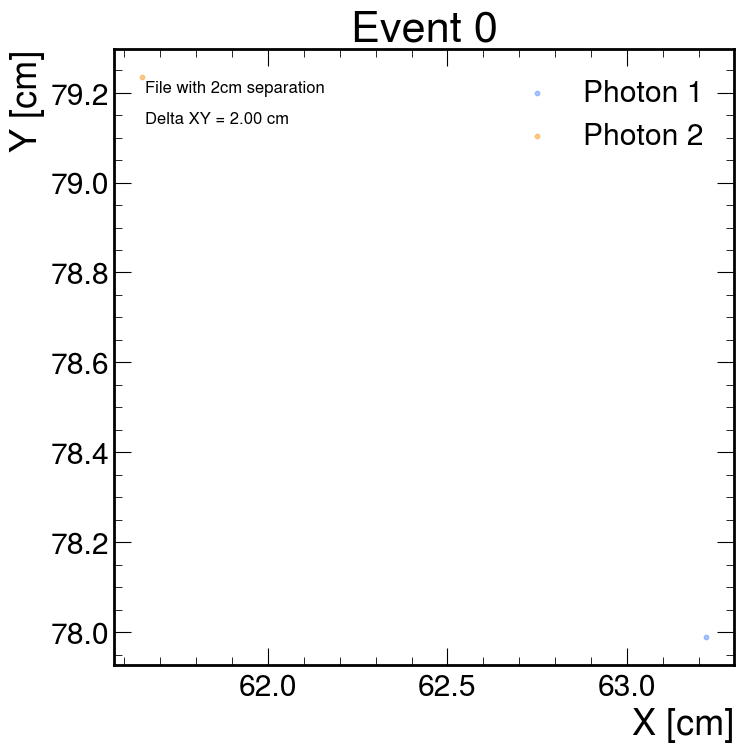

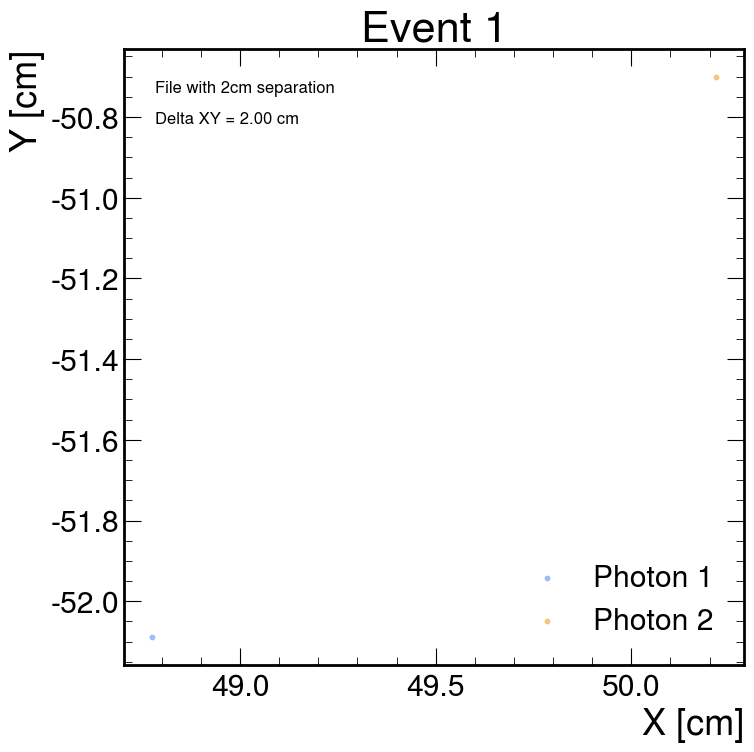

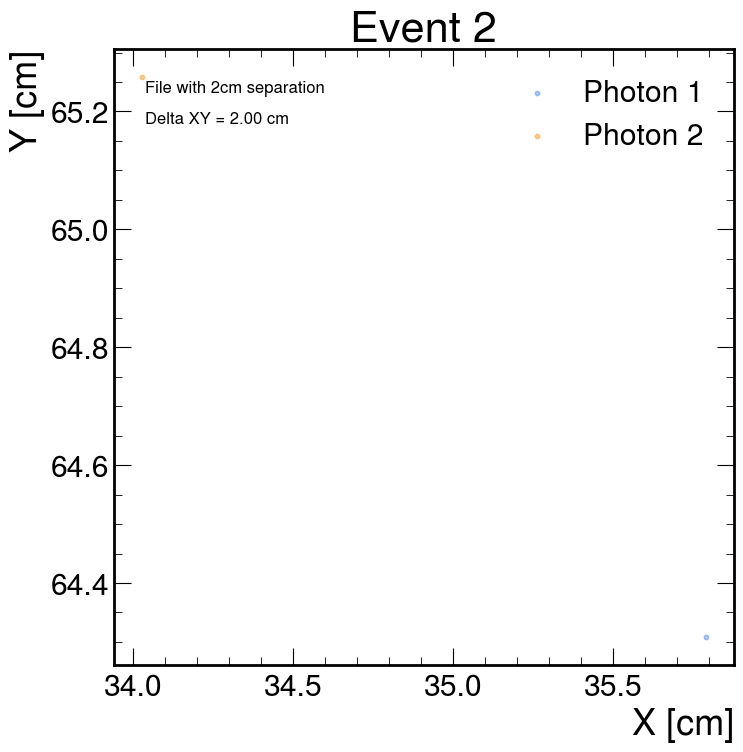

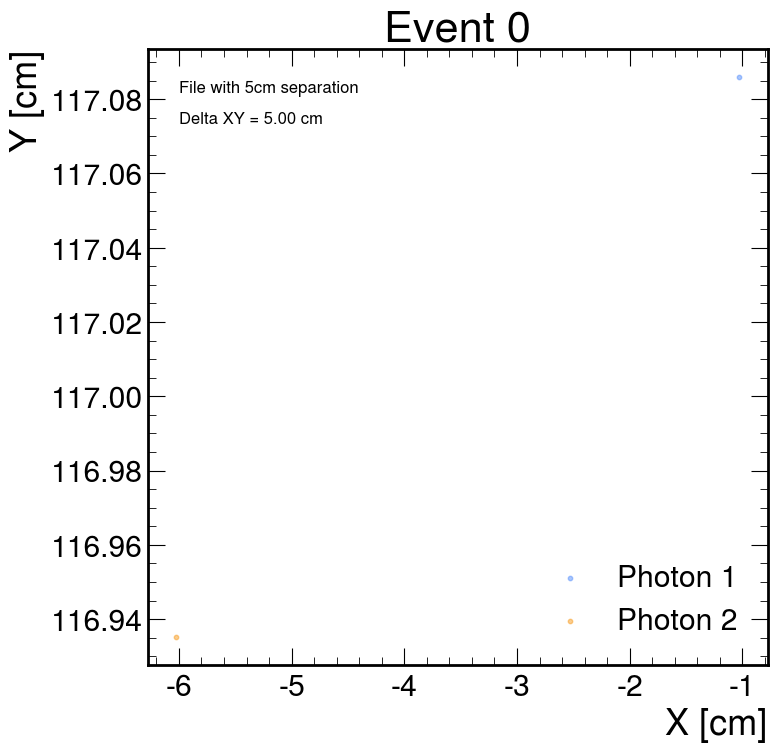

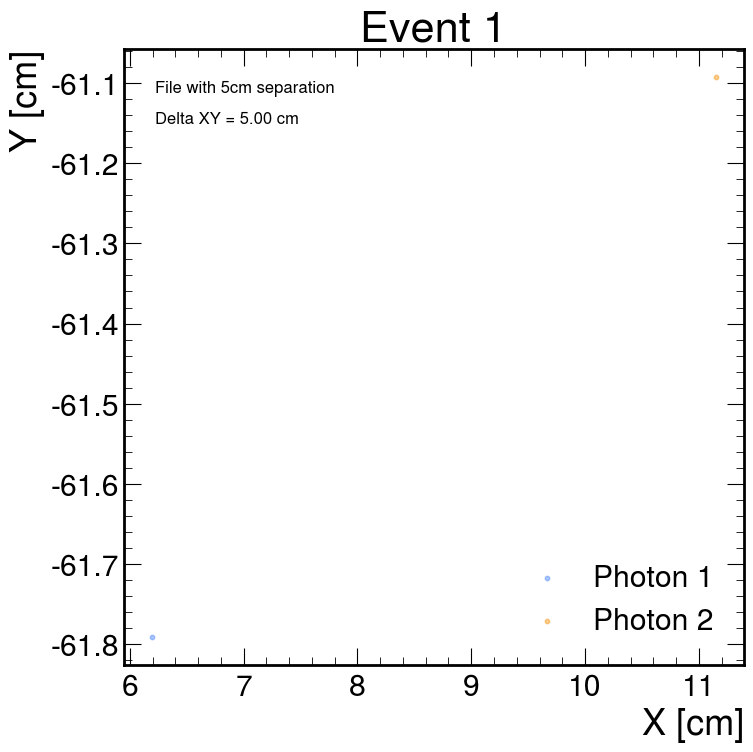

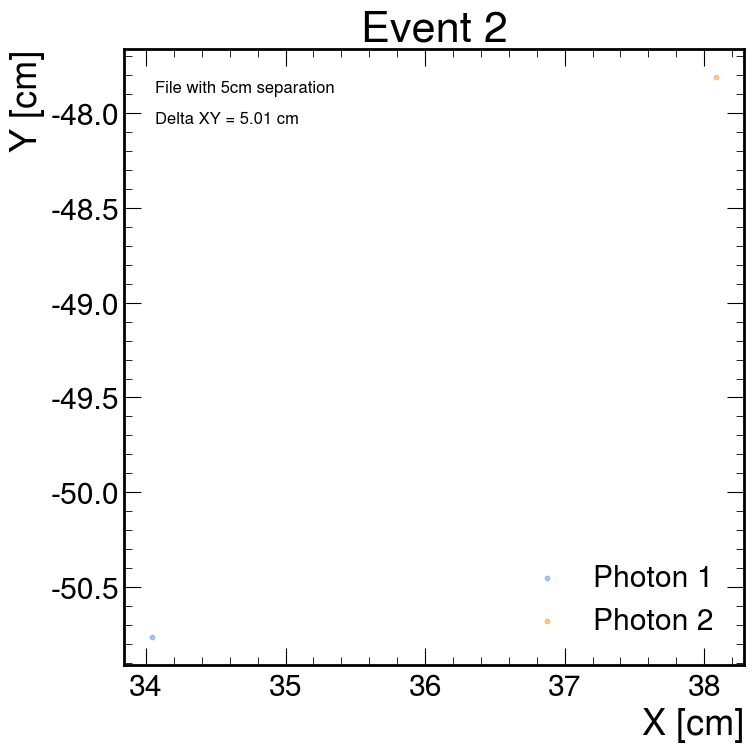

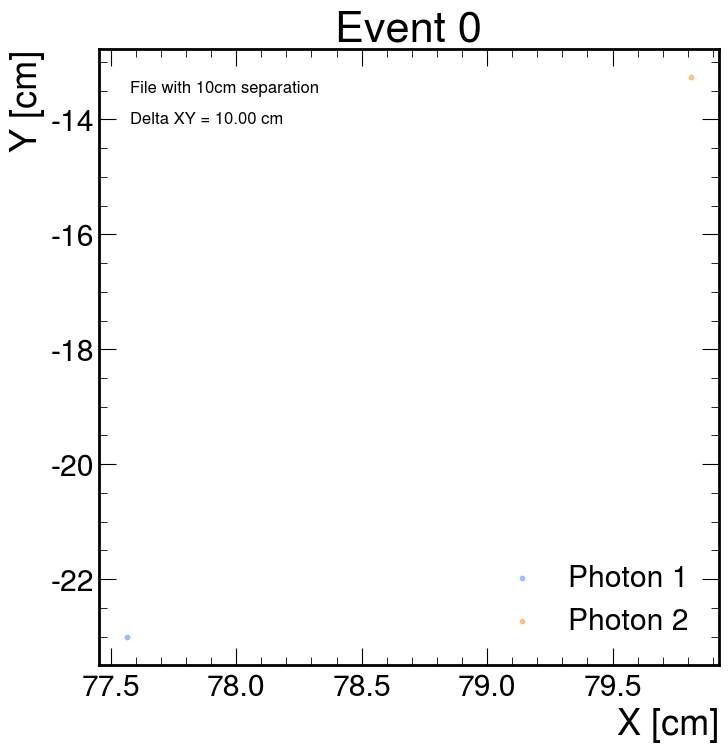

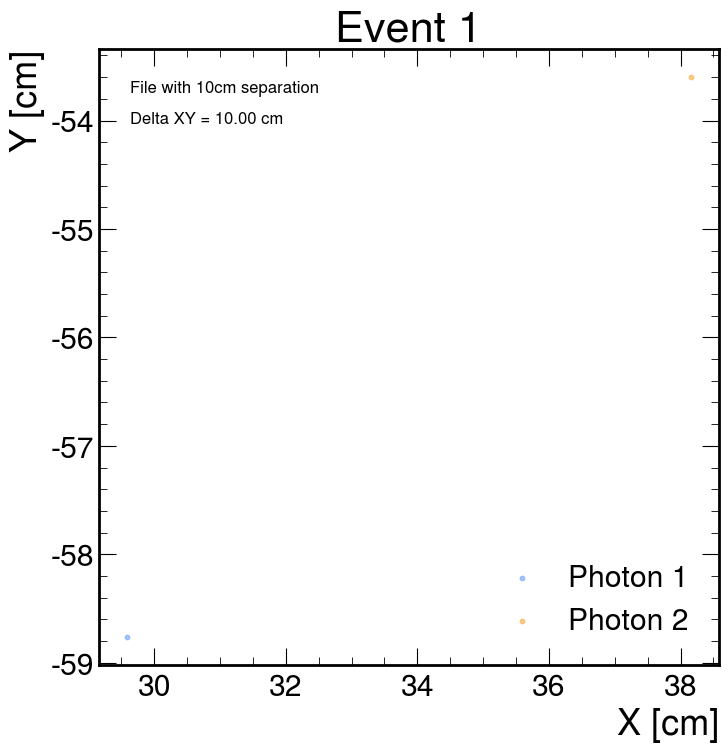

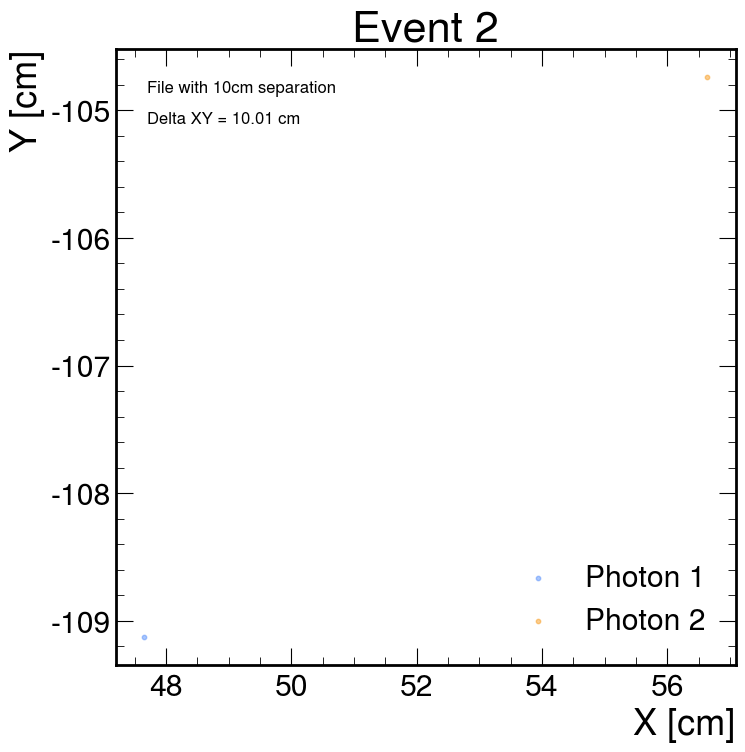

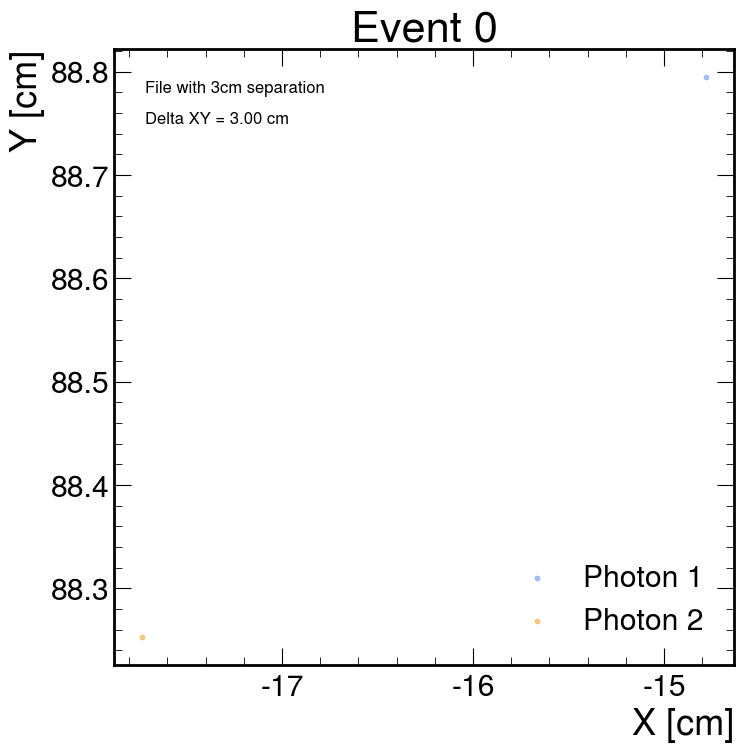

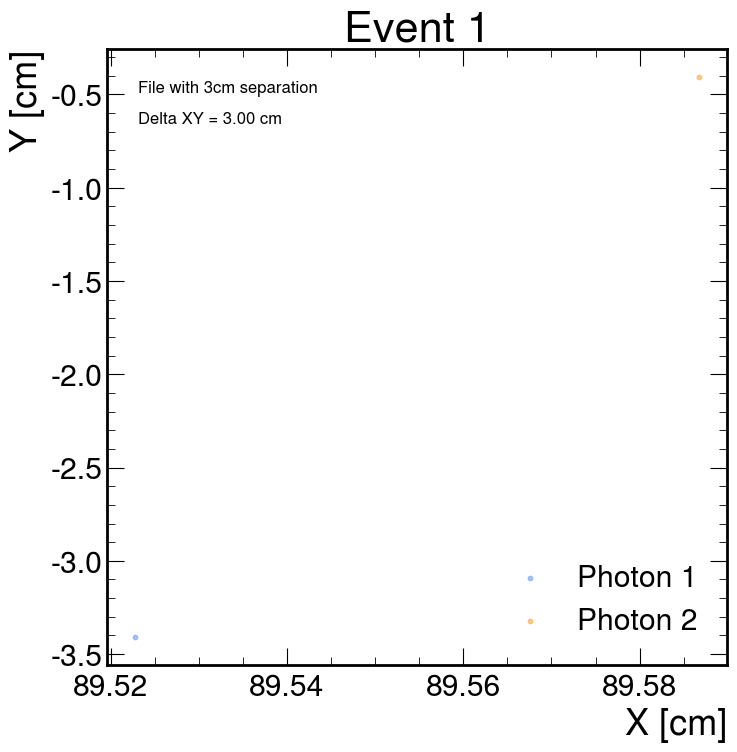

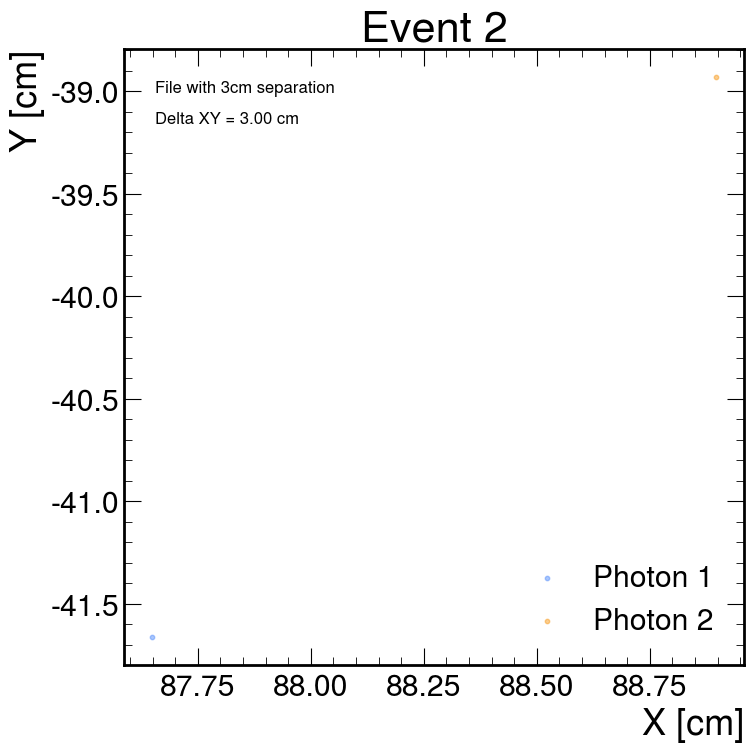

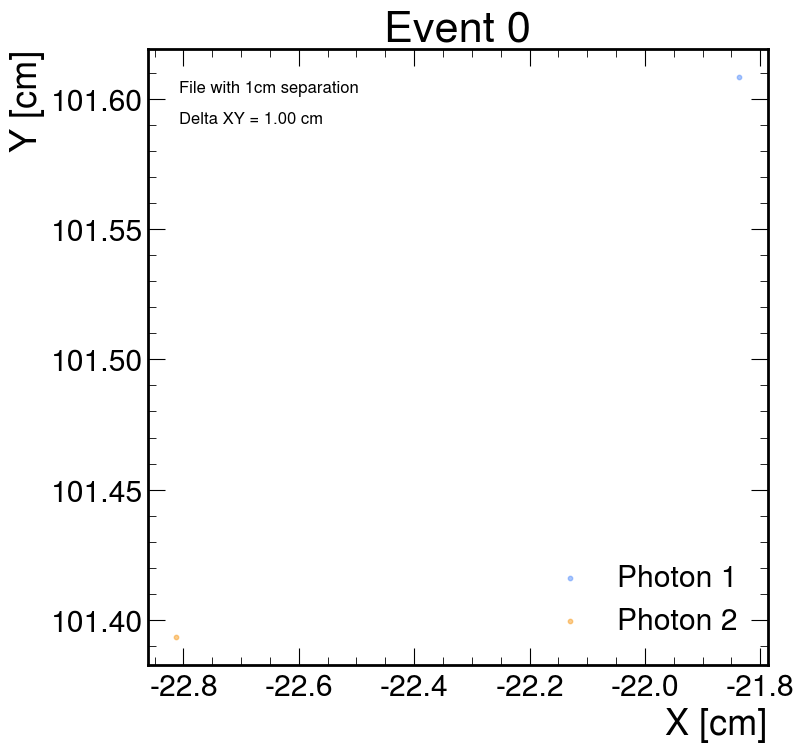

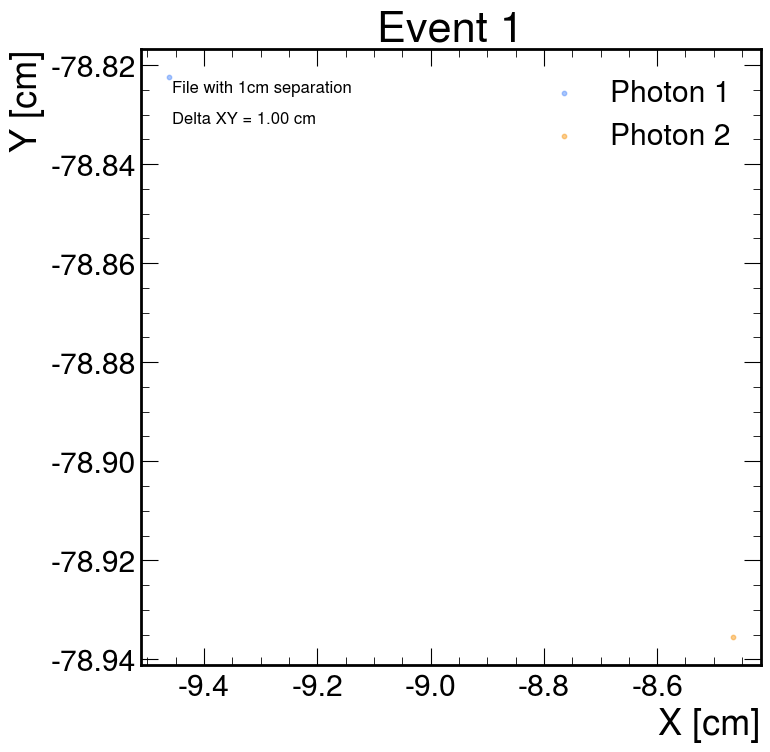

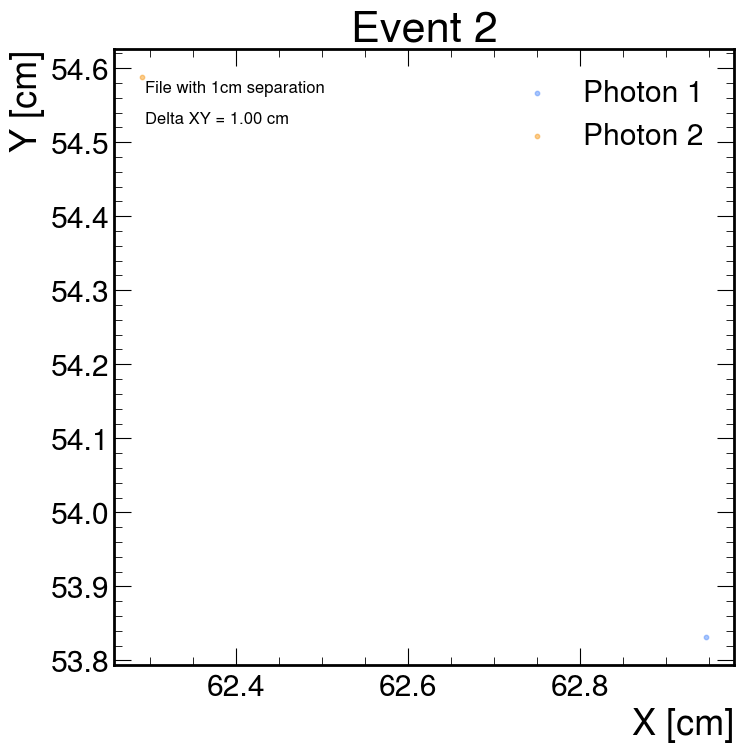

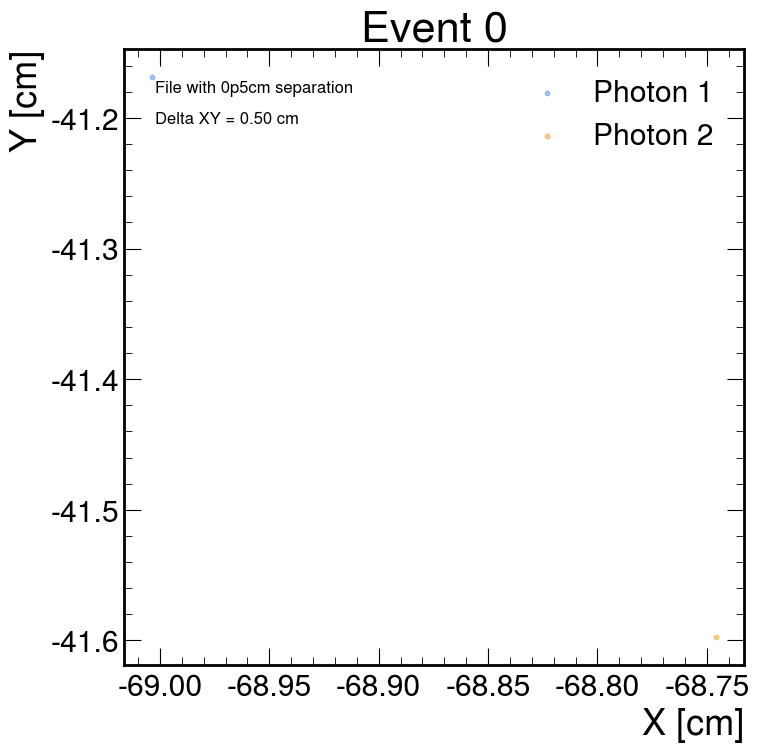

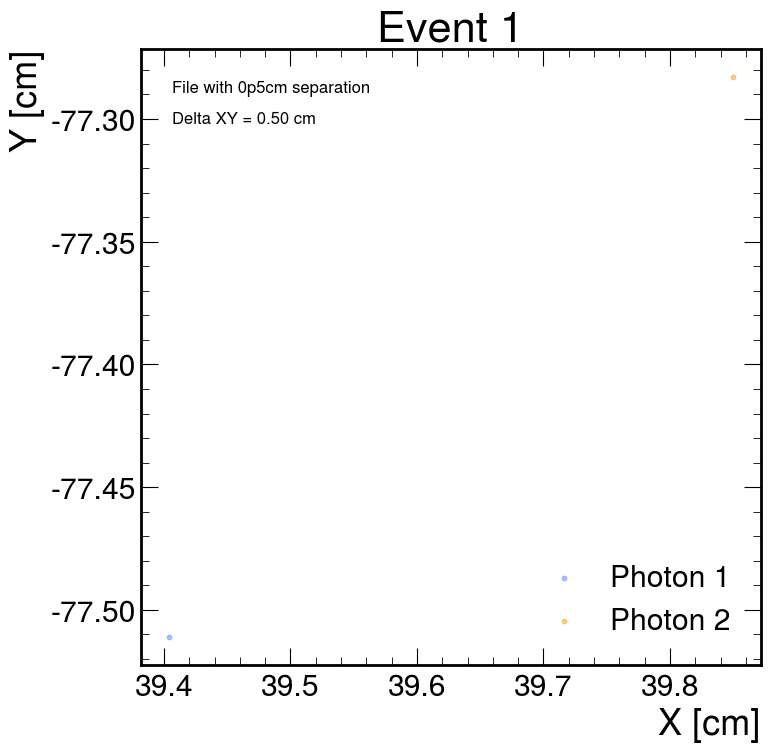

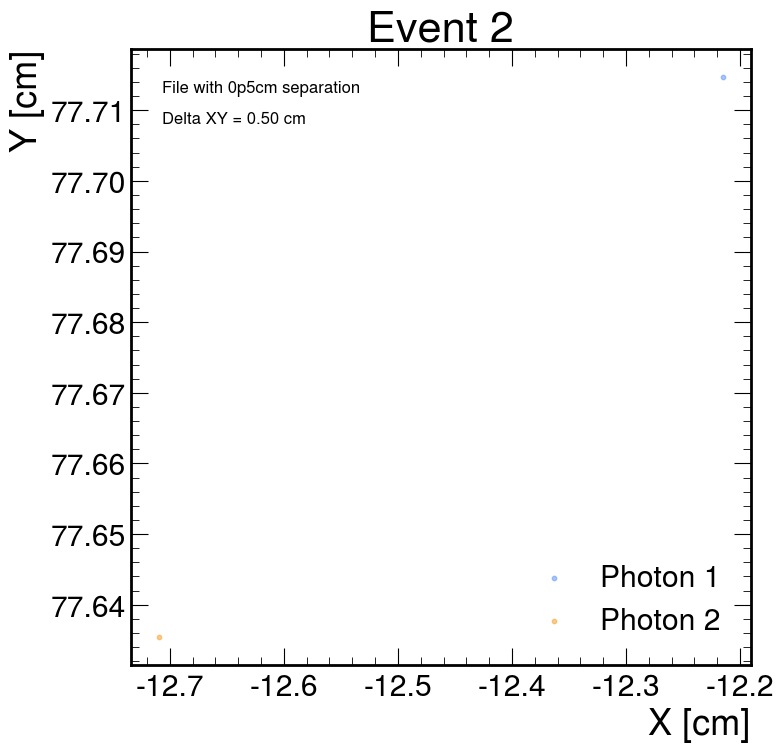

In [6]:
for distance, file in files.items():
    df = ak.from_parquet(file)
    mask = ak.num(df.TruthCB.TruthCB_energy) == 2
    x = df.TruthCB.TruthCB_boundaryX[mask]
    y = df.TruthCB.TruthCB_boundaryY[mask]
    for ievt in range(3):
        fig, ax = plt.subplots(1, 1, figsize=(8, 8))
        ax.scatter(x[ievt, 0], y[ievt, 0], s=10, alpha=0.5, label="Photon 1")
        ax.scatter(x[ievt, 1], y[ievt, 1], s=10, alpha=0.5, label="Photon 2")
        dxy = np.sqrt((x[ievt, 0] - x[ievt, 1])**2 + (y[ievt, 0] - y[ievt, 1])**2)
        ax.text(0.05, 0.95, "File with {} separation".format(distance), transform=ax.transAxes, fontsize=12, verticalalignment='top')
        ax.text(0.05, 0.90, "Delta XY = {:.2f} cm".format(dxy), transform=ax.transAxes, fontsize=12, verticalalignment='top')
        ax.set_xlabel("X [cm]")
        ax.set_ylabel("Y [cm]")
        ax.set_title("Event {}".format(ievt))
        ax.legend()

In [7]:
df.fields

['LayerCluster',
 'HGCalGenPart',
 'TICLCand',
 'Candidate2Tracksters',
 'ticlTrackstersCLUEstering',
 'ticlTracksterLinks',
 'ticlTrackstersRecovery',
 'ticlTracksterInterpretations',
 'ticlSimTracksters',
 'ticlSimTrackstersFromCPs',
 'SimTICLCand',
 'SimCandidate2Tracksters',
 'LinksToSimTSByHits',
 'SimTSToLinksByHits',
 'LinksToSimTSByLCs',
 'SimTSToLinksByLCs',
 'LinksToSimTSCPByHits',
 'SimTSCPToLinksByHits',
 'LinksToSimTSCPByLCs',
 'SimTSCPToLinksByLCs',
 'CLUEsteringToSimTSByHits',
 'SimTSToCLUEsteringByHits',
 'CLUEsteringToSimTSByLCs',
 'SimTSToCLUEsteringByLCs',
 'CLUEsteringToSimTSCPByHits',
 'SimTSCPToCLUEsteringByHits',
 'CLUEsteringToSimTSCPByLCs',
 'SimTSCPToCLUEsteringByLCs',
 'InterpretationsToSimTSByHits',
 'SimTSToInterpretationsByHits',
 'InterpretationsToSimTSByLCs',
 'SimTSToInterpretationsByLCs',
 'InterpretationsToSimTSCPByHits',
 'SimTSCPToInterpretationsByHits',
 'InterpretationsToSimTSCPByLCs',
 'SimTSCPToInterpretationsByLCs',
 'TruthCB',
 'TruthFG',
 'La

In [8]:
df.TICLCand.TICLCand_energy

<Array [[123], [], [267, ... [280, 5.77], []] type='1000 * var * float32'>

In [9]:
df.TruthCB.TruthCB_energy

<Array [[24.7, 89.6], [], ... [82.5, 191], []] type='1000 * var * float32'>

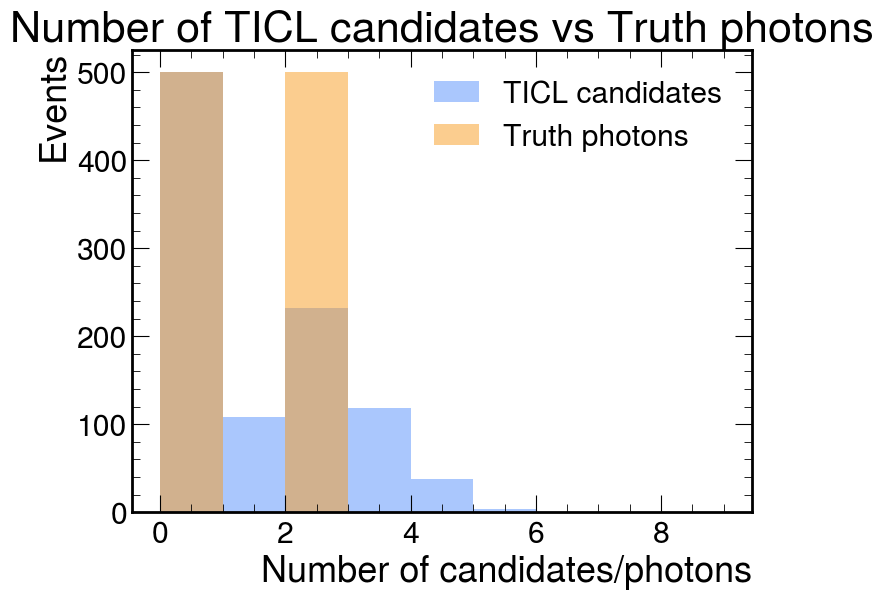

In [10]:
ncand = ak.num(df.TICLCand.TICLCand_energy)
ntruth = ak.num(df.TruthCB.TruthCB_energy)
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.hist(ncand, bins=np.arange(0, 10, 1), alpha=0.5, label="TICL candidates")
ax.hist(ntruth, bins=np.arange(0, 10, 1), alpha=0.5, label="Truth photons")
ax.set_xlabel("Number of candidates/photons")
ax.set_ylabel("Events")
ax.set_title("Number of TICL candidates vs Truth photons")
ax.legend();

In [20]:
df.TICLCand.TICLCand_energy[ntruth == 2].tolist()[:10]

[[123.10136413574219],
 [266.5680847167969],
 [64.09980010986328, 1.7595372200012207],
 [163.74380493164062],
 [224.0735321044922, 8.252358436584473],
 [98.66647338867188, 1.810071587562561],
 [65.0771484375],
 [170.9580841064453, 1.8531105518341064],
 [103.0950698852539, 7.181680202484131],
 [169.6662139892578, 1.0628671646118164]]

In [21]:
df.TruthCB.TruthCB_energy[ntruth == 2].tolist()[:10]

[[24.69874382019043, 89.59180450439453],
 [169.7808380126953, 186.26402282714844],
 [30.047544479370117, 36.858863830566406],
 [123.47113800048828, 50.39433288574219],
 [114.0894546508789, 133.0923614501953],
 [62.3071403503418, 34.39875030517578],
 [20.169326782226562, 49.434627532958984],
 [36.76070022583008, 132.10426330566406],
 [79.93730926513672, 44.209381103515625],
 [149.2189178466797, 87.43013763427734]]

In [ ]:
df.TruthFG.fields

['TruthFG_isSignal',
 'TruthFG_hasBoundary',
 'TruthFG_pdgId',
 'TruthFG_bunchCrossing',
 'TruthFG_eventIndex',
 'TruthFG_parentGraphId',
 'TruthFG_genRootGraphId',
 'TruthFG_graphId',
 'TruthFG_levelFlags',
 'TruthFG_charge',
 'TruthFG_pt',
 'TruthFG_eta',
 'TruthFG_phi',
 'TruthFG_energy',
 'TruthFG_boundaryX',
 'TruthFG_boundaryY',
 'TruthFG_boundaryZ',
 'TruthFG_boundaryT',
 'TruthFG_boundaryPx',
 'TruthFG_boundaryPy',
 'TruthFG_boundaryPz',
 'TruthFG_boundaryE',
 'TruthFG_boundaryPt',
 'TruthFG_boundaryEta',
 'TruthFG_boundaryPhi',
 'TruthFG_simEnergyHGCAL',
 'TruthFG_isPileup',
 'TruthFG_hasHGCALHits']

In [27]:
df.TruthFG.TruthFG_boundaryZ[0]

<Array [321, 321, 322, 322, 324, 324] type='6 * float32'>

In [32]:
df.TruthFG.TruthFG_parentGraphId[0]

<Array [-1, -1, 1, 1, 0, 0] type='6 * int32'>

In [28]:
df.TruthCB.TruthCB_boundaryZ[0]

<Array [321, 321] type='2 * float32'>

In [36]:
df.TruthFG.TruthFG_bunchCrossing[0]

<Array [0, 0, 0, 0, 0, 0] type='6 * int32'>

In [ ]:
df.